In [31]:
import os
import ssl

# Set FACE_MASK_DATASET_PATH to a local dataset root to skip the download.
dataset_path = os.environ.get("FACE_MASK_DATASET_PATH")
if dataset_path is None:
    ca_bundle = ssl.get_default_verify_paths().cafile
    if ca_bundle and os.path.isfile(ca_bundle):
        os.environ.setdefault("REQUESTS_CA_BUNDLE", ca_bundle)
    import kagglehub
    dataset_path = kagglehub.dataset_download(
        "prasoonkottarathil/face-mask-lite-dataset"
    )

if not os.path.isdir(os.path.join(dataset_path, "without_mask")):
    raise FileNotFoundError(
        f"Expected a 'without_mask' folder inside dataset directory: {dataset_path}"
    )

prasoonkottarathil_face_mask_lite_dataset_path = dataset_path
print(f"Data source ready: {dataset_path}")

Data source ready: /Users/Z002YK9/.cache/kagglehub/datasets/prasoonkottarathil/face-mask-lite-dataset/versions/1


# Introduction
<img src = 'https://cdn-images-1.medium.com/max/900/1*TKr1dtcNgJCA8uYY1OhmSg.png'>

Generative Adversarial Networks (GANs) are generative models. They are uses unsupervised technique to generate new things. GAN models learns pattern in input data in such a way that they can generate new sample which resemble with the input data. The main aim of generative adversarial network is to match generated distribution with the original data distribution.

GANs are an exciting and rapidly changing field, delivering generative models ability to generate realistic examples across a range of problem domains, most notably in image-to-image translation tasks such as translating photos of summer to winter or day to night,coloring images and in generating fake photos that even human cannot categorized as fake image.
This <a href = 'https://thispersondoesnotexist.com/'> site </a> uses GAN to generate fake human faces which are similar to real human

### Components of GANs
<b> Generator </b>: Generator are neural network that learns to generate data which resemble with the input distribution. The generator model take fixed dimension random vector from Gaussian distribution as input and generate the sample out of it which resemble with input.

<b> Discriminator </b>: Discriminator are simple neural network that distinguish fake and real data.The discriminator model takes an example from the domain as input (real or generated) and predicts a binary class label of real or fake.

Generative adversarial networks are based on a game theoretic scenario in which the generator network must compete against an adversary. The generator network directly produces samples. Its adversary, the discriminator network, attempts to distinguish between samples drawn from the training data and samples drawn from the generator.

# Working of GANs
<img src = 'https://cdn.analyticsvidhya.com/wp-content/uploads/2017/06/11000153/g1.jpg'>

First of all we take batch of random vector from the Gaussian distribution and generate fake image out of it using generator. Since generator isn't trained so generated image donot resemble with the real input distribution. We take batches of image from the input distribution along with generated fake images and fed it to discriminator so that it learns to distinguish between real and fake images.
Now, after training discriminator, we take the batch of images that generator generated and fed them through discriminator again (here we donot fed real images), discriminator will provide an output probabilities, these values are then compared with the probability that the generator should generated (ie 1), error is calculated and backpropagated through the generator and the weight are updated.
This above process is repeated until generated images resemble with the input distribution.

## Application of GANs

## 1. Generating fake faces
<img src = "https://3qeqpr26caki16dnhd19sv6by6v-wpengine.netdna-ssl.com/wp-content/uploads/2019/06/Examples-of-Photorealistic-GAN-Generated-Faces.png">

## 2. Generate Examples for Image Datasets

## 3. Face Aging
<img src = 'https://www.baycare.net/media/5076/botox-aging-face-plastic-surgery.jpg' height = '600px' width = '500px'>



## 4. Super Resolution
<img src = 'https://miro.medium.com/max/700/1*E-JmUwv7zbwjzFm1hJLxPA.png'>


## 5. Image-to-Image Translation
<img src = 'https://3qeqpr26caki16dnhd19sv6by6v-wpengine.netdna-ssl.com/wp-content/uploads/2019/06/Example-of-Photographs-of-Daytime-Cityscapes-to-Nighttime-with-pix2pix.png'>

## 6.  Photos to Emojis
<img src = 'https://3qeqpr26caki16dnhd19sv6by6v-wpengine.netdna-ssl.com/wp-content/uploads/2019/06/Example-of-Celebrity-Photographs-and-GAN-Generated-Emojis.png'>




## 7.Text to image Translation

<img src = 'https://3qeqpr26caki16dnhd19sv6by6v-wpengine.netdna-ssl.com/wp-content/uploads/2019/06/Example-of-Textual-Descriptions-and-GAN-Generated-Photographs-of-Birds.png'>


## 8. Generate Cartoon characters
<img src = 'https://3qeqpr26caki16dnhd19sv6by6v-wpengine.netdna-ssl.com/wp-content/uploads/2019/06/Example-of-GAN-Generated-Anime-Character-Faces.png'>
   


## Objective: To generate fake faces of human

## Import necessary Libraries

In [32]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.utils import img_to_array
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
from tqdm import tqdm
import re

gpu_devices = tf.config.list_physical_devices("GPU")
print(f"TensorFlow {tf.__version__}")
print(f"GPU devices: {gpu_devices or 'None (using CPU)'}")

TensorFlow 2.18.1
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Load data
Here I have used face-mask-lite-dataset, out of available 10000 images i have only use 9090 image. I have read image using opencv since opencv reads image in bgr format i have converted it back to rgb format using cvtColor function. These images are resize into 128 by 128 using resize function and are finally converted to array and are appended in empty array

In [33]:
# to get the files in proper order
def sorted_alphanumeric(data):
    convert = lambda text: int(text) if text.isdigit() else text.lower()
    alphanum_key = lambda key: [convert(c) for c in re.split('([0-9]+)',key)]
    return sorted(data,key = alphanum_key)
# defining the size of the image
SIZE = 128
_img = []
path = os.path.join(prasoonkottarathil_face_mask_lite_dataset_path, 'without_mask')
files = os.listdir(path)
files = sorted_alphanumeric(files)
for i in tqdm(files):
        if i == 'seed9090.png':
            break
        else:
            img = cv2.imread(path + '/'+i,1)
            # open cv reads images in BGR format so we have to convert it to RGB
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            #resizing image
            img = cv2.resize(img, (SIZE, SIZE))
            img = (img - 127.5) / 127.5
            imh = img.astype(float)
            _img.append(img_to_array(img))

 91%|█████████ | 9090/10000 [02:00<00:12, 75.73it/s]


## Visailze our images

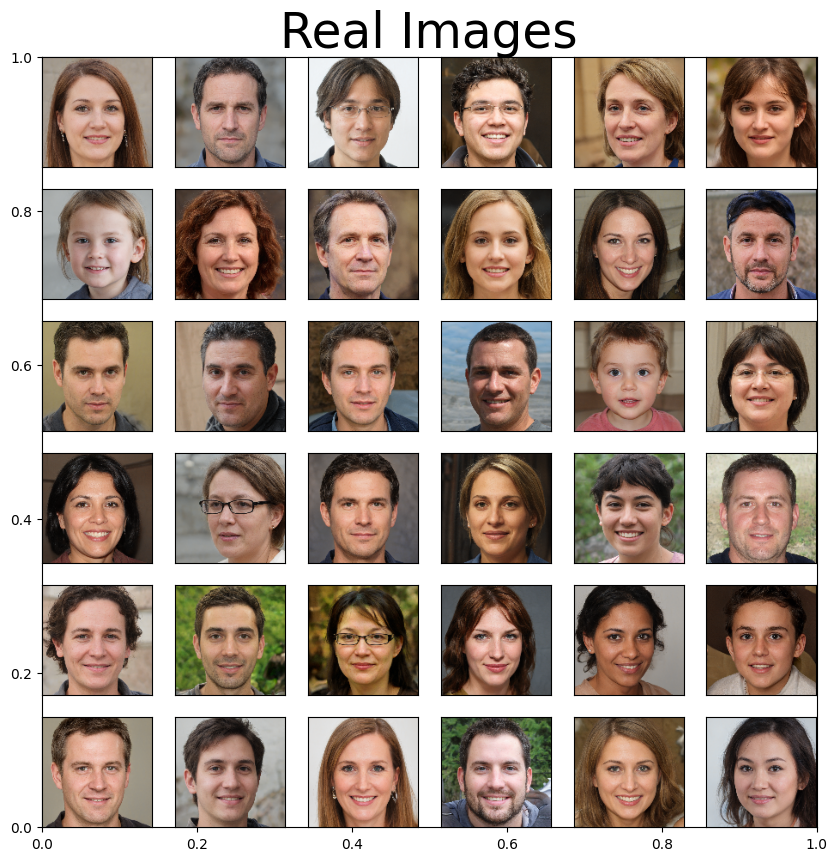

In [34]:
def plot_images(sqr = 5):
    plt.figure(figsize = (10,10))
    plt.title("Real Images",fontsize = 35)
    for i in range(sqr * sqr):
        plt.subplot(sqr,sqr,i+1)
        plt.imshow(_img[i]*0.5 + 0.5 )
        plt.xticks([])
        plt.yticks([])

# to plot images
plot_images(6)


Here, i have defined batch size so that these batches of images can be fed directly to the discriminator network

In [35]:
batch_size = 32
dataset=tf.data.Dataset.from_tensor_slices(np.array(_img)).batch(batch_size)

# Generator
Here, I have defined generator network. It take random vector from normal distribution as input. This random vector is passed through dense layer and is reshaped and is finally fed through Convolution layers. Here, convolution layers does downsampling of our latent vector, after series of convolution batch normalization and leakyrelu layer our downsampled latent vector is upsampled using Conv2DTranspose.

The final output layer of Generator generate 128 by 128 by 3 image. The final layer of generator uses hyperbolic tangent as activation to squash the value in between -1 and 1. Generator model looks like simple autoencoder model, where input data is downsampled first and is finally upsampled .

In [36]:
latent_dim = 100
def Generator():
    model = tf.keras.Sequential()
    model.add(layers.Dense(128*128*3, use_bias=False, input_shape=(latent_dim,)))
    model.add(layers.Reshape((128,128,3)))
    # downsampling
    model.add(tf.keras.layers.Conv2D(128,4, strides=1, padding='same',kernel_initializer='he_normal', use_bias=False))
    model.add(tf.keras.layers.Conv2D(128,4, strides=2, padding='same',kernel_initializer='he_normal', use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())
    model.add(tf.keras.layers.Conv2D(256,4, strides=1, padding='same',kernel_initializer='he_normal', use_bias=False))
    model.add(tf.keras.layers.Conv2D(256,4, strides=2, padding='same',kernel_initializer='he_normal', use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())
    model.add(tf.keras.layers.Conv2DTranspose(512, 4, strides=1,padding='same',kernel_initializer='he_normal',use_bias=False))
    model.add(tf.keras.layers.Conv2D(512,4, strides=2, padding='same',kernel_initializer='he_normal', use_bias=False))

    model.add(tf.keras.layers.LeakyReLU())
    #upsampling
    model.add(tf.keras.layers.Conv2DTranspose(512, 4, strides=1,padding='same',kernel_initializer='he_normal',use_bias=False))
    model.add(tf.keras.layers.Conv2DTranspose(512, 4, strides=2,padding='same',kernel_initializer='he_normal',use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())
    model.add(tf.keras.layers.Conv2DTranspose(256, 4, strides=1,padding='same',kernel_initializer='he_normal',use_bias=False))
    model.add(tf.keras.layers.Conv2DTranspose(256, 4, strides=2,padding='same',kernel_initializer='he_normal',use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())

    model.add(tf.keras.layers.Conv2DTranspose(128, 4, strides=2,padding='same',kernel_initializer='he_normal',use_bias=False))
    model.add(tf.keras.layers.Conv2DTranspose(128, 4, strides=1,padding='same',kernel_initializer='he_normal',use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.Conv2DTranspose(3,4,strides = 1, padding = 'same',activation = 'tanh'))



    return model

In [37]:
generator = Generator()
generator.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 49152)          │     4,915,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 128, 128, 128)  │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 64, 64, 128)    │       262,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 64, 64, 256)    │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 256)    │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 32, 32, 512)    │     2,097,152 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 512)    │     4,194,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 16, 16, 512)    │     4,194,304 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 32, 32, 512)    │     4,194,304 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32, 32, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 32, 32, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 32, 32, 256)    │     2,097,152 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_12             │ (None, 64, 64, 256)    │     1,048,576 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 64, 64, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 25,379,843 (96.82 MB)

 Trainable params: 25,377,283 (96.81 MB)

 Non-trainable params: 2,560 (10.00 KB)

# Discriminator
Here, discriminator model take 128 by 128 by 3 image that can be real or generated. This input image is downsampled using Convolution layer and is finally flattened and is fed to single neuron so that it can distinguish real and fake image. Since, final layer uses sigmoid function as activation, it output value in between 0 and 1. Here value greater than 0.5 refers to real and less than 0.5 refers to fake image. The output of discriminator is used in training of generator.

In [38]:
def Discriminator():
    model = tf.keras.models.Sequential()
    model.add(tf.keras.layers.Input((SIZE, SIZE, 3)))
    model.add(tf.keras.layers.Conv2D(128,4, strides=2, padding='same',kernel_initializer='he_normal', use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())
    model.add(tf.keras.layers.Conv2D(128,4, strides=2, padding='same',kernel_initializer='he_normal', use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())
    model.add(tf.keras.layers.Conv2D(256,4, strides=2, padding='same',kernel_initializer='he_normal', use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())
    model.add(tf.keras.layers.Conv2D(256,4, strides=2, padding='same',kernel_initializer='he_normal', use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.LeakyReLU())
    model.add(tf.keras.layers.Conv2D(512,4, strides=2, padding='same',kernel_initializer='he_normal', use_bias=False))
    model.add(tf.keras.layers.LeakyReLU())
    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(1,activation = 'sigmoid'))
    return model



In [39]:
discriminator = Discriminator()
discriminator.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 64, 64, 128)    │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_13 (LeakyReLU)      │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 32, 32, 128)    │       262,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_14 (LeakyReLU)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 16, 16, 256)    │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_15 (LeakyReLU)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 8, 8, 256)      │     1,048,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_16 (LeakyReLU)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 4, 4, 512)      │     2,097,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_17 (LeakyReLU)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         8,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,949,569 (15.07 MB)

 Trainable params: 3,948,033 (15.06 MB)

 Non-trainable params: 1,536 (6.00 KB)

### Let's plot image generated by generator before training

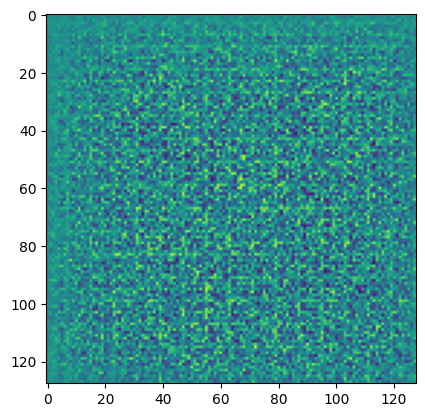

In [40]:
noise = np.random.normal(-1,1,(1,100))
img = generator(noise)
plt.imshow(img[0,:,:,0])
plt.show()

### Defining loss function and optimizer

In [41]:
#optimizer = tf.keras.optimizers.RMSprop(
#        learning_rate=.0001,
#        clipvalue=1.0,
#        decay=1e-8
#    )
#cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits = True)

In [42]:
# Define separate optimizers
generator_optimizer = tf.keras.optimizers.RMSprop(
    learning_rate=0.0001,
    clipvalue=1.0
)
discriminator_optimizer = tf.keras.optimizers.RMSprop(
    learning_rate=0.0001,
    clipvalue=1.0
)

In [43]:
#def generator_loss(fake_output):
#    return cross_entropy(tf.ones_like(fake_output),fake_output)
#def discriminator_loss(fake_output, real_output):
#    fake_loss = cross_entropy(tf.zeros_like(fake_output),fake_output)
#    real_loss = cross_entropy(tf.ones_like(real_output),real_output)
#    return fake_loss + real_loss

In [44]:
# Define your loss
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=False)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(fake_output, real_output):
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    return fake_loss + real_loss

### Defining training steps

In [45]:
# Training step
@tf.function
def train_steps(images):
    noise = tf.random.normal([batch_size, latent_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        fake_output = discriminator(generated_images, training=True)
        real_output = discriminator(images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(fake_output, real_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    # Apply gradients using correct optimizers
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    loss = {
        'gen_loss': gen_loss,
        'disc_loss': disc_loss
    }

    return loss


## function to plot generated images


In [46]:
from datetime import datetime

GENERATED_IMAGES_DIR = os.environ.get("GAN_OUTPUT_DIR", "generated_images")
os.makedirs(GENERATED_IMAGES_DIR, exist_ok=True)


def plot_generated_images(square = 5, epochs = 0, save = True, show = True, prefix = "generated"):
  generated = []

  plt.figure(figsize = (10,10))
  for i in range(square * square):
    if epochs != 0:
        if(i == square //2):
            plt.title("Generated Image at Epoch:{}\n".format(epochs), fontsize = 32, color = 'black')
    plt.subplot(square, square, i+1)
    noise = np.random.normal(0,1,(1,latent_dim))
    img = generator(noise)
    generated.append(np.array(img[0]))
    plt.imshow(np.clip((img[0,...]+1)/2, 0, 1))

    plt.xticks([])
    plt.yticks([])
    plt.grid()

  if save:
      tag = "epoch{:03d}".format(epochs) if epochs else datetime.now().strftime("%Y%m%d-%H%M%S")
      grid_path = os.path.join(GENERATED_IMAGES_DIR, "{}_{}_grid.png".format(prefix, tag))
      plt.savefig(grid_path, bbox_inches = 'tight')
      print("Saved grid of {} image(s) to: {}".format(len(generated), os.path.abspath(grid_path)))

  if show:
      plt.show()
  else:
      plt.close()

  return generated

In [47]:
import time

def train(epochs, dataset, save_images_every = 1, sample_square = 3):
    for epoch in range(epochs):
        print(f'Epoch : {epoch + 1}')
        start = time.time()

        for images in dataset:
            loss = train_steps(images)

        print(" Time:{}".format(np.round(time.time() - start, 2)))
        print("Generator Loss: {} Discriminator Loss: {}".format(loss['gen_loss'], loss['disc_loss']))

        # persist a sample of the generated images for this epoch
        if save_images_every and (epoch + 1) % save_images_every == 0:
            plot_generated_images(
                square = sample_square,
                epochs = epoch + 1,
                save = True,
                show = False,
                prefix = "training"
            )

## Training

In [48]:
train(12,dataset)
# i had train model previously for more than 10 epochs so generated images are quiet good

Epoch : 1
 Time:165.93
Generator Loss: 7.20757532119751 Discriminator Loss: 0.0008312353165820241
Saved 9 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images
Epoch : 2
 Time:179.91
Generator Loss: 6.242248058319092 Discriminator Loss: 0.0021808710880577564
Saved 9 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images
Epoch : 3
 Time:187.46
Generator Loss: 6.330202102661133 Discriminator Loss: 0.001936224289238453
Saved 9 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images
Epoch : 4


2026-11-11 12:02:10.631561: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


 Time:193.66
Generator Loss: 15.543123245239258 Discriminator Loss: 1.8626448650138627e-07
Saved 9 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images
Epoch : 5
 Time:196.37
Generator Loss: 20.753013610839844 Discriminator Loss: 0.0
Saved 9 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images
Epoch : 6
 Time:201.79
Generator Loss: 0.0009149381658062339 Discriminator Loss: 7.318497180938721
Saved 9 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images
Epoch : 7
 Time:197.81
Generator Loss: 7.110748767852783 Discriminator Loss: 1.3718963861465454
Saved 9 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images
Epoch : 8
 Time:199.75
Generator Loss: 1

# Some Generated Images


Saved 1 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images


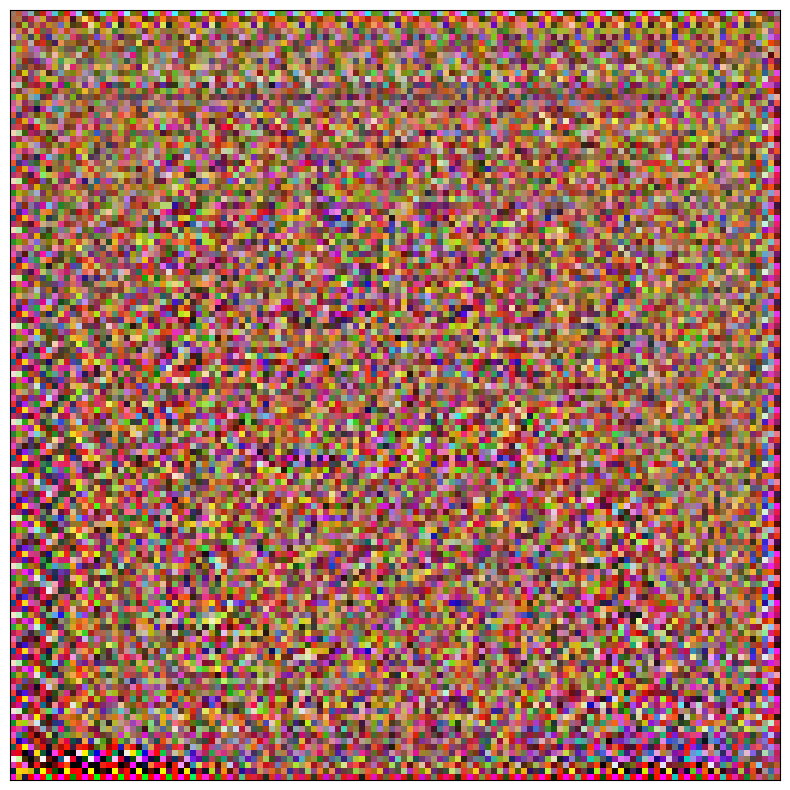

[array([[[ 0.23790537, -0.05905551, -0.23715462],
         [ 0.40742806, -0.2901    , -0.5876533 ],
         [ 0.36567736, -0.28827202,  0.33916107],
         ...,
         [ 0.15986618, -0.5457284 , -0.6904776 ],
         [ 0.41742924, -0.6878001 ,  0.1577041 ],
         [ 0.05560414,  0.07315722,  0.25615242]],
 
        [[ 0.33788192, -0.15298043, -0.39582196],
         [ 0.36560342, -0.08332525, -0.43543217],
         [-0.10821464, -0.68833447, -0.46602622],
         ...,
         [ 0.13678417, -0.30608988, -0.7838609 ],
         [-0.27254364, -0.4190095 , -0.7230525 ],
         [ 0.14612357, -0.27060097, -0.383335  ]],
 
        [[-0.02719135, -0.10079557, -0.16234954],
         [ 0.06062952, -0.57434124, -0.78021765],
         [ 0.19999313,  0.54393566, -0.6711587 ],
         ...,
         [ 0.0838501 ,  0.2834128 , -0.0956063 ],
         [ 0.08944363,  0.4351889 , -0.73929274],
         [ 0.76086575, -0.35181105, -0.14716862]],
 
        ...,
 
        [[ 0.76617897, -0.5696589 

In [49]:
plot_generated_images(1)

Saved 4 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images


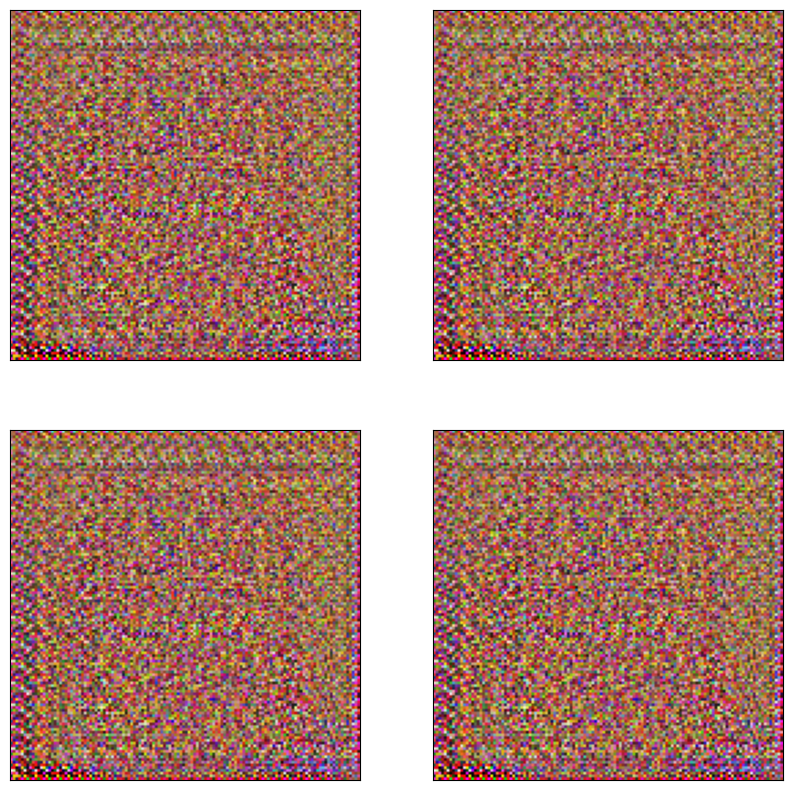

[array([[[ 0.23953237, -0.05719318, -0.2450035 ],
         [ 0.4106226 , -0.29062837, -0.58860457],
         [ 0.36818725, -0.2901388 ,  0.34823272],
         ...,
         [ 0.13695988, -0.5450255 , -0.6854308 ],
         [ 0.40448695, -0.68522274,  0.15286925],
         [ 0.05550132,  0.06456832,  0.24197294]],
 
        [[ 0.33241817, -0.1510081 , -0.40244842],
         [ 0.37107208, -0.07559916, -0.42968205],
         [-0.11294923, -0.6945088 , -0.4731699 ],
         ...,
         [ 0.14701791, -0.29425842, -0.78010094],
         [-0.25900868, -0.4228318 , -0.7259988 ],
         [ 0.15368281, -0.2665367 , -0.3879932 ]],
 
        [[-0.029915  , -0.09481794, -0.17110299],
         [ 0.06382644, -0.57065296, -0.7823688 ],
         [ 0.19955902,  0.5461168 , -0.68201   ],
         ...,
         [ 0.07572083,  0.2925711 , -0.10746925],
         [ 0.07464262,  0.43392107, -0.72625464],
         [ 0.750567  , -0.35826412, -0.16877586]],
 
        ...,
 
        [[ 0.7744609 , -0.56836426

In [50]:
plot_generated_images(2)

Saved 25 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images


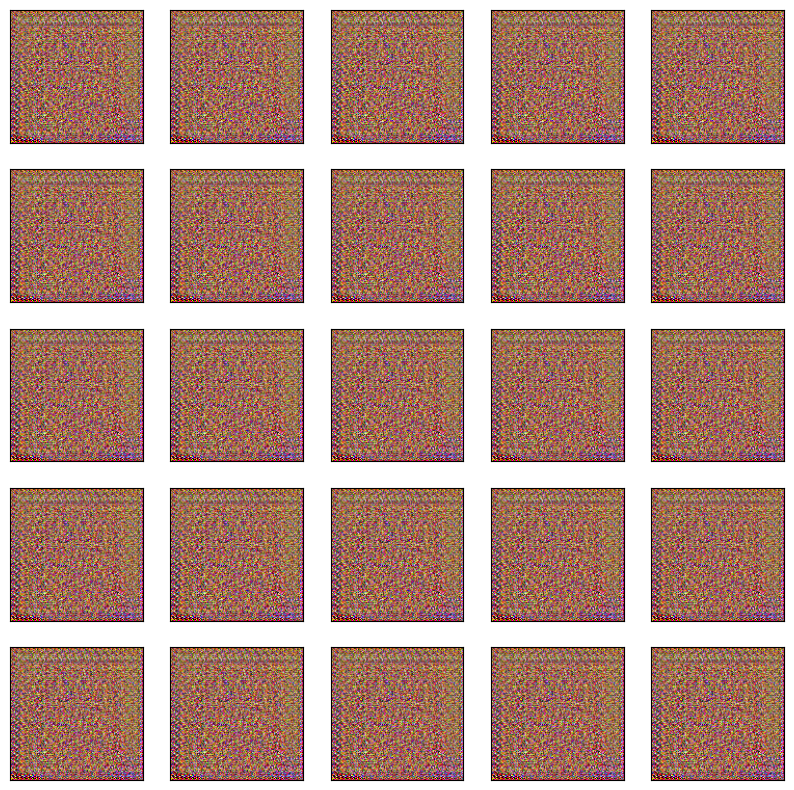

[array([[[ 0.23476471, -0.06098324, -0.2412533 ],
         [ 0.40883243, -0.2950594 , -0.5943747 ],
         [ 0.36791846, -0.2869985 ,  0.34742278],
         ...,
         [ 0.15497424, -0.54360634, -0.6886647 ],
         [ 0.4169742 , -0.68486756,  0.15074329],
         [ 0.04610543,  0.06431603,  0.2437615 ]],
 
        [[ 0.3372364 , -0.15686177, -0.39693046],
         [ 0.36815614, -0.08701062, -0.43290707],
         [-0.11844342, -0.69551533, -0.46271226],
         ...,
         [ 0.13995042, -0.29030308, -0.78095275],
         [-0.25374264, -0.41750643, -0.7245132 ],
         [ 0.14840034, -0.26406452, -0.38971165]],
 
        [[-0.0247334 , -0.09204538, -0.15863447],
         [ 0.06400809, -0.57000893, -0.7844875 ],
         [ 0.20371331,  0.54955596, -0.6660171 ],
         ...,
         [ 0.0677347 ,  0.27676326, -0.10013215],
         [ 0.07876985,  0.42780837, -0.7349129 ],
         [ 0.7515244 , -0.36418107, -0.1665376 ]],
 
        ...,
 
        [[ 0.7727482 , -0.56933755

In [51]:
plot_generated_images(5)

Saved 49 image(s) and grid to: /Users/Z002YK9/learning_projects/vizuara-genai/minorinai/01-class-notes/08-generating-fake-faces-gan/generated_images


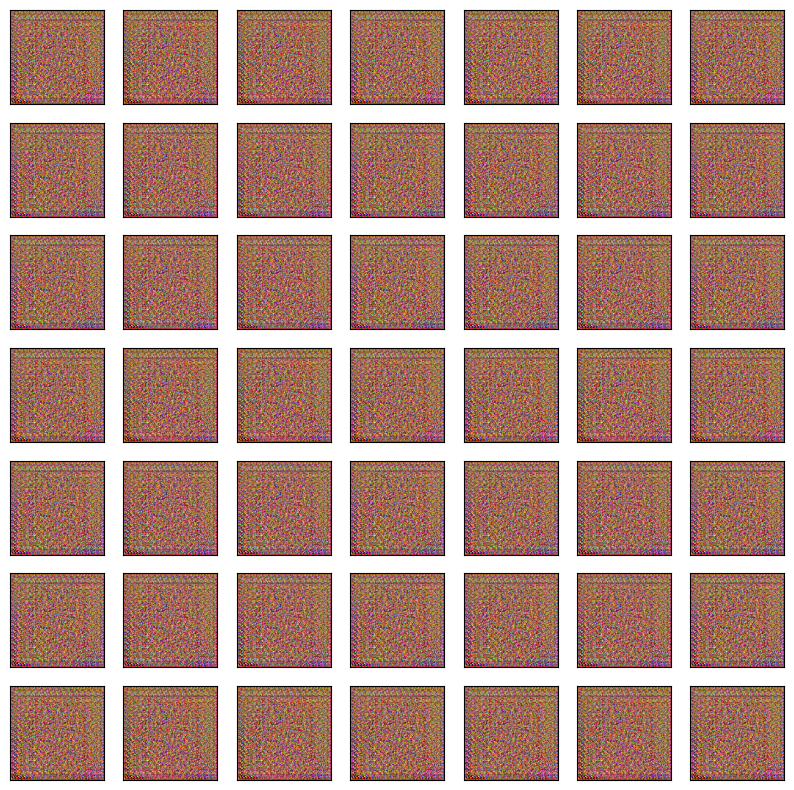

[array([[[ 0.23621899, -0.05557868, -0.23964053],
         [ 0.40842804, -0.293614  , -0.587307  ],
         [ 0.36760476, -0.28600746,  0.34452033],
         ...,
         [ 0.14709094, -0.5789611 , -0.70419616],
         [ 0.40921   , -0.69284034,  0.15729432],
         [ 0.02818241,  0.06693562,  0.25707355]],
 
        [[ 0.3356159 , -0.15143485, -0.39122847],
         [ 0.36850184, -0.08040667, -0.433388  ],
         [-0.11106756, -0.6884794 , -0.46798027],
         ...,
         [ 0.16400188, -0.284559  , -0.7807115 ],
         [-0.25150952, -0.43447876, -0.72951293],
         [ 0.15868627, -0.25970396, -0.39710462]],
 
        [[-0.02704578, -0.09796989, -0.15865348],
         [ 0.0695327 , -0.5656241 , -0.7798839 ],
         [ 0.20196715,  0.5404848 , -0.66715086],
         ...,
         [ 0.06479405,  0.3397148 , -0.09870975],
         [ 0.06558014,  0.45279944, -0.722487  ],
         [ 0.76176804, -0.3652037 , -0.20638634]],
 
        ...,
 
        [[ 0.7723889 , -0.5717796 

In [52]:
plot_generated_images(7)

In [53]:
generator.save('generator.h5')
discriminator.save("discriminator.h5")

#### ref: <a href = 'https://machinelearningmastery.com/what-are-generative-adversarial-networks-gans/'> machinelearningmastery </a>, <a href = 'https://towardsdatascience.com/generative-adversarial-network-gan-for-dummies-a-step-by-step-tutorial-fdefff170391'> towardsdatascience </a>

### Thanks for your visit
## Any suggestion to improve generated images is really appreciated
## Feel free to comment and upvote.....
# Thank You